# trunk_shred_wave

**Question.** Does a DeepONet-style SHRED (SHRED's recurrent encoder as the *branch*, a coordinate MLP over
space and time as the *trunk*) train on the 1D wave, and can a wave-equation physics loss be satisfied
without hurting reconstruction?

**Setup.** `configs/experiment/trunk_shred_wave.yaml`, 1D wave trajectory 0 (256 grid points, 500 steps,
c = 2, L = 2, u(0) = u(L) = 0), N = 8 probes, lags = 10, seeds 0, 1, 2, clean training and evaluation,
1000 epochs with early stopping. Status: tentative.

## The model

* **Sample.** Window *i* holds the probe readings at frames *i … i+9*; the target is the full field at the
  last frame (identical to SHRED).
* **Branch.** SHRED's GRU reads the window → hidden state → linear → coefficients **b** ∈ R⁶⁴.
* **Trunk.** tanh MLP **T**(x, τ) ∈ R⁶⁴; τ is time relative to the window's last frame, τ ∈ [−9 dt, 0].
  x enters through 16 Fourier features sin/cos(kπx/L).
* **Output.** û(x, τ) = **b** · **T**(x, τ) + bias, a continuous field over the window's space-time slab.
  Evaluated at the grid x and τ = 0 and MinMax-scaled inside the model, so loss, validation and metrics
  equal SHRED's.
* **Physics loss** (`trunk_shred_pinn`, λ = 1e-3), on 64 random (x, τ) per sample, in physical units:
  λ · ( mean[((û_ττ − c² û_xx)/ω₁²)²] + mean[û(0 or L, τ)²] ), derivatives by autograd, ω₁ = πc/L.

Why this fits the wave: the exact solution in a window is
u(x, t₀+τ) = Σₖ sin(kπx/L) [Aₖ cos ωₖτ + Bₖ sin ωₖτ], ωₖ = πck/L, i.e. a DeepONet with 20 trunk functions,
each of which satisfies the PDE and the BCs on its own.

**Runs.** `shred` (baseline), `trunk_shred` (λ = 0: architecture only), `trunk_shred_pinn` (λ = 1e-3), and
the search that set the defaults: Fourier features 0 / 8 (`trunk_shred_noff`, `trunk_shred_ff8`, λ = 0) and
physics weight 1e-2 / 1e-4 (`trunk_shred_pinn_strong`, `trunk_shred_pinn_weak`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display
from get_shredded import plots as gp
from get_shredded.model import wave_residual
from get_shredded.runner import (_build_model, load_arrays, load_config, load_results, load_seed_info,
                                 output_root, prepare_seed, run_name)

cfg = load_config(["+experiment=trunk_shred_wave", "data=wave"])
ROOT = output_root(cfg)
results = load_results(ROOT)
RUNS = [run_name(r) for r in cfg.runs]
SEEDS = list(cfg.eval.seeds)
MAIN = ["shred__clean", "trunk_shred__clean", "trunk_shred_pinn__clean"]
TRUNK = [r for r in RUNS if r.startswith("trunk")]
LABEL = {"shred__clean": "SHRED", "trunk_shred__clean": "trunk, no physics", "trunk_shred_pinn__clean": "trunk + physics",
         "trunk_shred_noff__clean": "trunk, no Fourier features", "trunk_shred_ff8__clean": "trunk, 8 frequencies",
         "trunk_shred_pinn_strong__clean": "trunk + physics λ=1e-2", "trunk_shred_pinn_weak__clean": "trunk + physics λ=1e-4"}
COLOR = {r: gp.method_color(r) for r in MAIN}
print(ROOT, "|", len(results), "completed (run, seed) results;", "missing:",
      [(r, s) for r in RUNS for s in SEEDS if (r, s) not in results])

/Users/kaspervanderhorst/projects/shred/get-shredded/outputs/trunk_shred_wave/wave | 21 completed (run, seed) results; missing: []


## Helpers: rebuild trained models

The runner saves `model.pt` per run; the model is rebuilt from the same config and seed data.

In [2]:
_seed_data = {}

def seed_data(seed):
    if seed not in _seed_data:
        _seed_data[seed] = prepare_seed(cfg, seed)
    return _seed_data[seed]

def load_model(run, seed):
    sd = seed_data(seed)
    model = _build_model(sd, cfg.methods[run.split("__")[0]], "cpu", cfg.data)
    model.load_state_dict(torch.load(ROOT / f"seed{seed}" / run / "model.pt"))
    return model.eval(), sd

def d(f, z):
    return torch.autograd.grad(f, z, torch.ones_like(f), create_graph=True)[0]

def residual_stats(model, sd, n_points=512, gen_seed=0):
    # Relative wave residual rms(u_tt - c^2 u_xx) / rms(c^2 u_xx) on random (x, tau) in the slab, test windows.
    g = torch.Generator().manual_seed(gen_seed)
    b = model.coefficients(torch.tensor(sd.windows[sd.test_idx])).detach()
    xs = (torch.rand(len(b), n_points, generator=g) * model.L).requires_grad_()
    ts = (-torch.rand(len(b), n_points, generator=g) * model.tau_span).requires_grad_()
    u = model.field(b, xs, ts)
    r = wave_residual(u, xs, ts, model.c)
    rel = (r.pow(2).mean() / (model.c**2 * d(d(u, xs), xs)).pow(2).mean()).sqrt().item()
    ub = model.field(b, torch.tensor([0.0, model.L]), torch.zeros(2)).detach()
    return rel, ub.pow(2).mean().sqrt().item()

RES = {(r, s): residual_stats(*load_model(r, s)) for r in TRUNK for s in SEEDS if (r, s) in results}

## Results (mean ± std over seeds)

Test error = relative L2 on the clean test windows (unscaled); train error on the clean training windows.
Residual = relative wave residual over the lag window on the test windows (0 = exact wave solution);
boundary = rms of û at x = 0, L (field rms ≈ 0.42).

In [3]:
def ms(vals, f="{:.4f}"):
    vals = np.asarray(vals, dtype=float)
    return (f + " ± " + f).format(vals.mean(), vals.std()) if len(vals) else "–"

rows = ["| Run | Fourier freq. | λ | test err | train err | residual | boundary | params | val checks |",
        "|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
for r in RUNS:
    seeds = [s for s in SEEDS if (r, s) in results]
    m = cfg.methods[r.split("__")[0]]
    met = [results[(r, s)]["metrics"] for s in seeds]
    res = [RES[(r, s)] for s in seeds if (r, s) in RES]
    rows.append(f"| {LABEL[r]} | {m.get('num_frequencies', '–')} | {m.get('physics_weight', '–')} "
                f"| {ms([x['clean']['err'] for x in met])} | {ms([x['train']['err'] for x in met])} "
                f"| {ms([x[0] for x in res], '{:.3f}') if res else '–'} | {ms([x[1] for x in res], '{:.4f}') if res else '–'} "
                f"| {met[0]['parameters']:,} | {ms([x['epochs_used'] for x in met], '{:.0f}')} |")
display(Markdown("\n".join(rows)))
display(Markdown("Per seed (test err): " + "; ".join(
    f"{LABEL[r]}: " + " / ".join(f"{results[(r, s)]['metrics']['clean']['err']:.4f}" for s in SEEDS) for r in MAIN)))

| Run | Fourier freq. | λ | test err | train err | residual | boundary | params | val checks |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| SHRED | – | – | 0.0285 ± 0.0065 | 0.0252 ± 0.0059 | – | – | 304,974 | 22 ± 4 |
| trunk, no physics | 16 | 0.0 | 0.0285 ± 0.0019 | 0.0268 ± 0.0017 | 0.964 ± 0.008 | 0.0035 ± 0.0001 | 53,825 | 31 ± 3 |
| trunk + physics | 16 | 0.001 | 0.0255 ± 0.0040 | 0.0254 ± 0.0033 | 0.024 ± 0.001 | 0.0023 ± 0.0005 | 53,825 | 46 ± 2 |
| trunk, no Fourier features | 0 | 0.0 | 0.4438 ± 0.0225 | 0.4449 ± 0.0122 | 8.736 ± 2.794 | 0.0447 ± 0.0029 | 51,841 | 49 ± 3 |
| trunk, 8 frequencies | 8 | 0.0 | 0.0352 ± 0.0055 | 0.0332 ± 0.0040 | 0.917 ± 0.014 | 0.0037 ± 0.0003 | 52,801 | 30 ± 2 |
| trunk + physics λ=1e-2 | 16 | 0.01 | 0.1291 ± 0.0046 | 0.1298 ± 0.0016 | 0.022 ± 0.000 | 0.0119 ± 0.0010 | 53,825 | 33 ± 2 |
| trunk + physics λ=1e-4 | 16 | 0.0001 | 0.0354 ± 0.0083 | 0.0343 ± 0.0092 | 0.089 ± 0.027 | 0.0040 ± 0.0009 | 53,825 | 31 ± 9 |

Per seed (test err): SHRED: 0.0302 / 0.0198 / 0.0355; trunk, no physics: 0.0259 / 0.0297 / 0.0300; trunk + physics: 0.0221 / 0.0312 / 0.0231

## Training curves

Validation relative L2 (every 20 epochs; early stopping after 5 checks without improvement). One line per seed.
Validation error is computed on the **MinMax-scaled** targets (as in `fit`), test error in physical units, so the two
are not comparable (best validation is ≈ half the test error for every run).

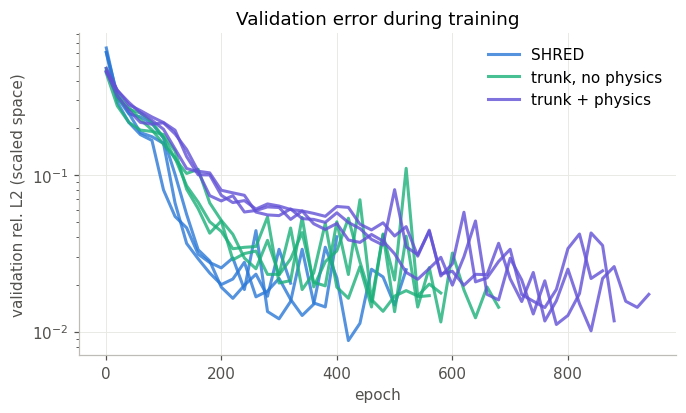

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for r in MAIN:
    for i, s in enumerate(SEEDS):
        h = load_arrays(ROOT, r, s)["val_history"]
        ax.plot([1] + [20 * k for k in range(1, len(h))], h, color=COLOR[r], alpha=0.8,
                label=LABEL[r] if i == 0 else None)
ax.set(yscale="log", xlabel="epoch", ylabel="validation rel. L2 (scaled space)", title="Validation error during training")
ax.legend(frameon=False)
gp.save(fig, ROOT, "training_curves"); plt.show()

## Reconstruction vs truth (τ = 0, seed 0)

The first four test windows; the lower row shows the pointwise error û − u.

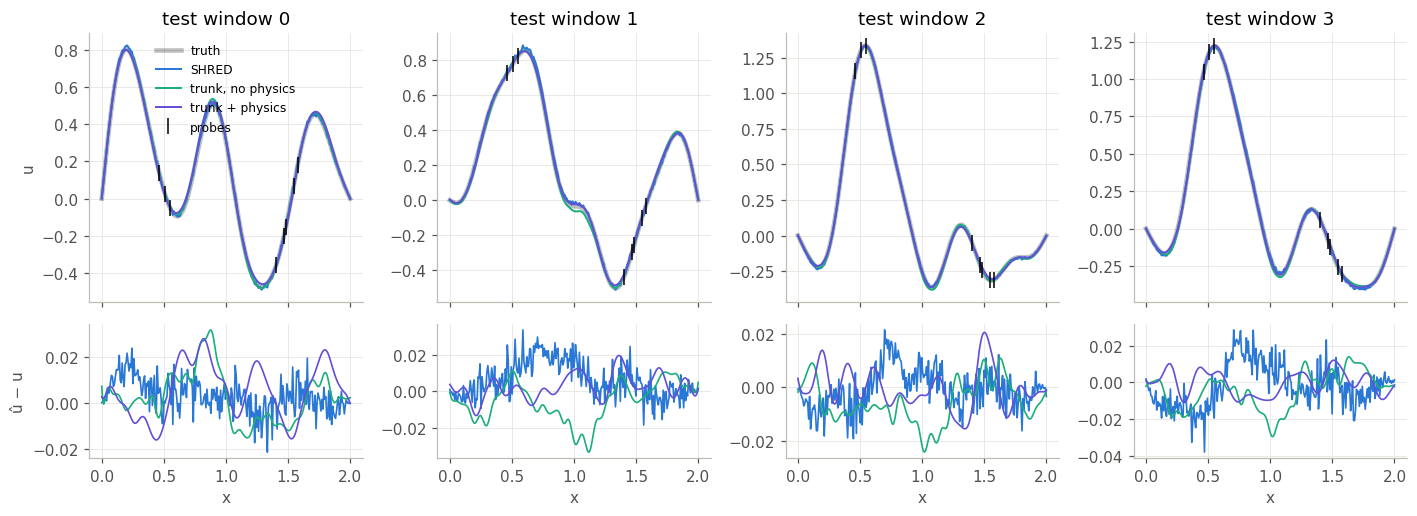

In [5]:
info = load_seed_info(ROOT, 0)
x = info["point_coordinates"][:, 0]
probes = x[info["locations"]]
recon = {r: load_arrays(ROOT, r, 0)["clean_panel_recon"] for r in MAIN}
fig, axes = plt.subplots(2, 4, figsize=(13, 4.8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
for w in range(4):
    truth = info["panel_truth"][w]
    axes[0, w].plot(x, truth, color="black", lw=3, alpha=0.25, label="truth")
    for r in MAIN:
        axes[0, w].plot(x, recon[r][w], color=COLOR[r], lw=1.3, label=LABEL[r])
        axes[1, w].plot(x, recon[r][w] - truth, color=COLOR[r], lw=1.1)
    axes[0, w].plot(probes, np.interp(probes, x, truth), "k|", ms=10, label="probes" if w == 0 else None)
    axes[0, w].set_title(f"test window {w}")
    axes[1, w].set_xlabel("x")
axes[0, 0].set_ylabel("u"); axes[1, 0].set_ylabel("û − u")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout(); gp.save(fig, ROOT, "reconstruction_panel"); plt.show()

## Space-time field over the lag window

Only τ = 0 is supervised; earlier τ are free (no physics) or constrained by the PDE (with physics).
Top: û(x, τ) and the residual u_ττ − c²u_xx (test window 0, seed 0). Bottom: test error at each of the
10 window frames, where the truth is known, averaged over test windows and seeds, next to a trivial baseline
that copies the true τ = 0 field to every earlier frame (it knows nothing about time). The table checks the
velocity directly: û_t at τ = 0 against the true u_t (backward difference of the last two frames).

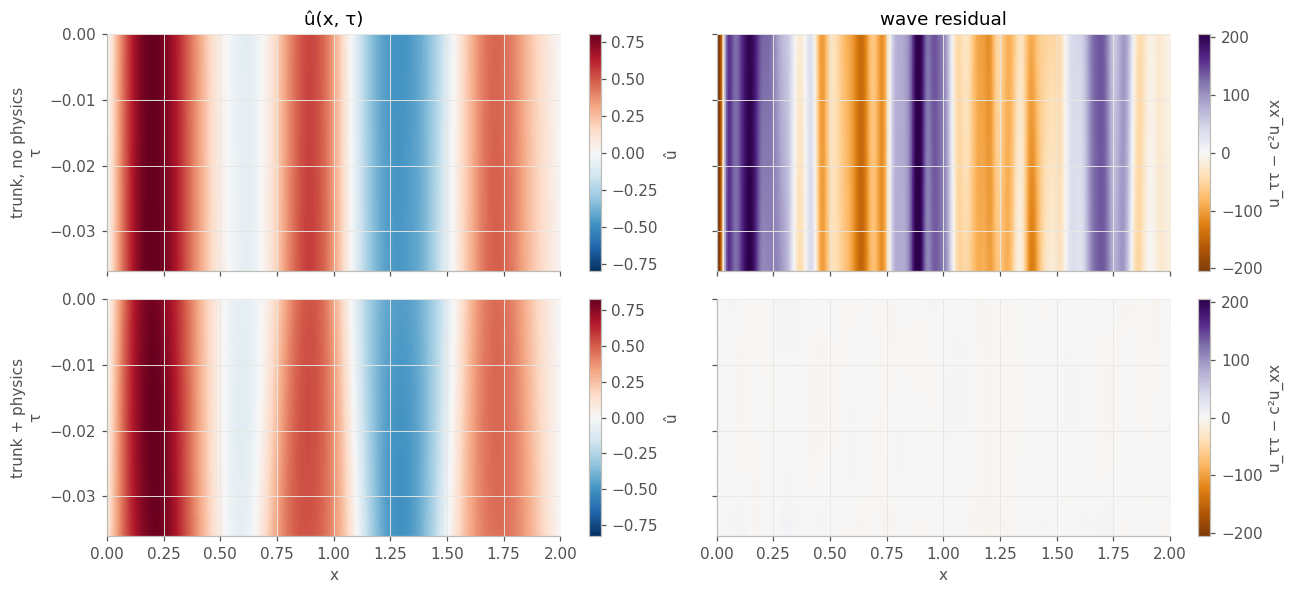

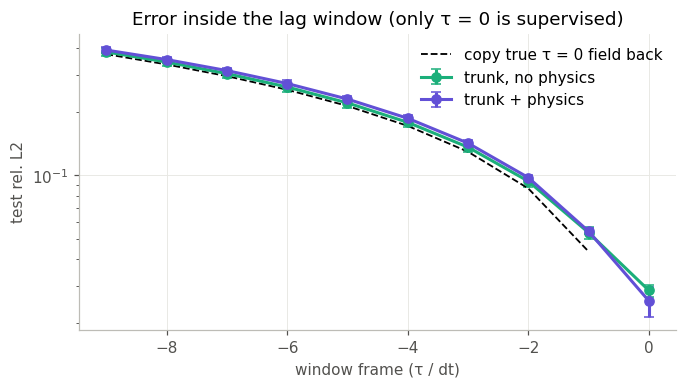

| Run | rel. error of û_t at τ = 0 | rms(û_t) / rms(u_t) |
|---|---:|---:|
| trunk, no physics | 1.02 ± 0.02 | 0.19 ± 0.05 |
| trunk + physics | 1.08 ± 0.02 | 0.42 ± 0.01 |

In [6]:
def slab(model, b, n_tau=60):
    tau = torch.linspace(-model.tau_span, 0.0, n_tau)
    X, T = torch.meshgrid(model.x_grid, tau, indexing="xy")  # (n_tau, n_x)
    xs, ts = X.reshape(1, -1).clone().requires_grad_(), T.reshape(1, -1).clone().requires_grad_()
    u = model.field(b, xs, ts)
    r = wave_residual(u, xs, ts, model.c)
    return tau, u.detach().reshape(n_tau, -1), r.detach().reshape(n_tau, -1)

maps = {}
for r in ["trunk_shred__clean", "trunk_shred_pinn__clean"]:
    model, sd = load_model(r, 0)
    maps[r] = slab(model, model.coefficients(torch.tensor(sd.windows[sd.test_idx[:1]])).detach())
lim = float(np.percentile(maps["trunk_shred__clean"][2].abs().numpy(), 98))  # shared residual scale, from the no-physics model
fig, axes = plt.subplots(2, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for row, (r, (tau, u, res)) in enumerate(maps.items()):
    ext = [0, model.L, tau[0].item(), 0]
    im = axes[row, 0].imshow(u, aspect="auto", origin="lower", extent=ext, cmap="RdBu_r",
                             vmin=-abs(u).max(), vmax=abs(u).max())
    fig.colorbar(im, ax=axes[row, 0], label="û")
    im = axes[row, 1].imshow(res, aspect="auto", origin="lower", extent=ext, cmap="PuOr", vmin=-lim, vmax=lim)
    fig.colorbar(im, ax=axes[row, 1], label="u_ττ − c²u_xx")
    axes[row, 0].set_ylabel(f"{LABEL[r]}\nτ")
axes[0, 0].set_title("û(x, τ)"); axes[0, 1].set_title("wave residual")
axes[1, 0].set_xlabel("x"); axes[1, 1].set_xlabel("x")
fig.tight_layout(); gp.save(fig, ROOT, "space_time_residual"); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
for r in ["trunk_shred__clean", "trunk_shred_pinn__clean"]:
    errs = []
    for s in SEEDS:
        model, sd = load_model(r, s)
        b = model.coefficients(torch.tensor(sd.windows[sd.test_idx])).detach()
        per_frame = []
        for j in range(sd.lags):  # frame j of window i is snapshot i + j; tau_j = (j - lags + 1) dt
            tau_j = torch.full_like(model.x_grid, (j - sd.lags + 1) * model.tau_span / (sd.lags - 1))
            pred = model.field(b, model.x_grid, tau_j).detach().numpy()
            truth = sd.load_X[sd.test_idx + j]
            per_frame.append(np.linalg.norm(pred - truth) / np.linalg.norm(truth))
        errs.append(per_frame)
    errs = np.array(errs)
    ax.errorbar(np.arange(-sd.lags + 1, 1), errs.mean(0), yerr=errs.std(0), color=COLOR[r], marker="o",
                capsize=3, label=LABEL[r])
copy = np.array([[np.linalg.norm(sd.load_X[sd.test_idx + sd.lags - 1] - sd.load_X[sd.test_idx + j])
                  / np.linalg.norm(sd.load_X[sd.test_idx + j]) for j in range(sd.lags)]
                 for sd in (seed_data(s) for s in SEEDS)])
ax.plot(np.arange(-sd.lags + 1, 1)[:-1], copy.mean(0)[:-1], "k--", lw=1.2, label="copy true τ = 0 field back")
ax.set(yscale="log", xlabel="window frame (τ / dt)", ylabel="test rel. L2",
       title="Error inside the lag window (only τ = 0 is supervised)")
ax.legend(frameon=False)
gp.save(fig, ROOT, "error_over_window"); plt.show()

def velocity_check(model, sd):
    # rel. error and rms ratio of the model's u_t at tau = 0 vs the true u_t (backward difference)
    b = model.coefficients(torch.tensor(sd.windows[sd.test_idx])).detach()
    t0 = torch.zeros(len(b), len(model.x_grid), requires_grad=True)
    u_t = d(model.field(b, model.x_grid.expand(len(b), -1), t0), t0).detach().numpy()
    true = (sd.load_X[sd.test_idx + sd.lags - 1] - sd.load_X[sd.test_idx + sd.lags - 2]) / (model.tau_span / (sd.lags - 1))
    return np.linalg.norm(u_t - true) / np.linalg.norm(true), np.sqrt((u_t**2).mean() / (true**2).mean())

rows = ["| Run | rel. error of û_t at τ = 0 | rms(û_t) / rms(u_t) |", "|---|---:|---:|"]
for r in ["trunk_shred__clean", "trunk_shred_pinn__clean"]:
    v = np.array([velocity_check(*load_model(r, s)) for s in SEEDS])
    rows.append(f"| {LABEL[r]} | {ms(v[:, 0], '{:.2f}')} | {ms(v[:, 1], '{:.2f}')} |")
display(Markdown("\n".join(rows)))

## Dispersion check against the analytic wave modes

Project û and û_ττ onto each spatial mode sin(kπx/L) to get aₖ(τ) and aₖ''(τ). An exact wave solution has
aₖ'' = −ωₖ² aₖ, so the effective frequency ω̂ₖ = √(−⟨aₖ'' aₖ⟩ / ⟨aₖ²⟩) must equal ωₖ = πck/L. Shown for k = 1..10
(modes 11+ carry no energy in the data; in trajectory 0, modes 7 and 9 carry ≈ 0 % of the energy, amplitudes
0.018 and 0.002, so their ω̂ is set by almost nothing).

A plain projection of û onto the 20 analytic functions is not shown: on a slab this thin any smooth τ-dependence
is ≈ a + bτ, which that span already contains, so both models score ≈ 0.999 and it does not separate them.

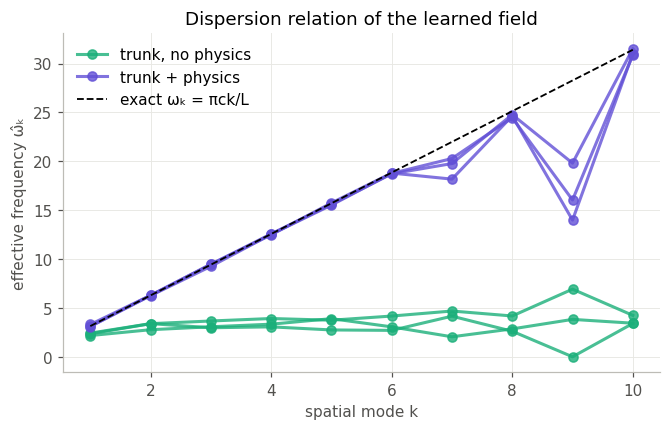

| Run | median abs(ω̂ₖ/ωₖ − 1), k = 1..10 |
|---|---:|
| trunk, no physics | 0.790 ± 0.025 |
| trunk + physics | 0.010 ± 0.004 |

In [7]:
K = 10

def modal_analysis(model, sd, n_tau=20):
    b = model.coefficients(torch.tensor(sd.windows[sd.test_idx])).detach()
    tau = torch.linspace(-model.tau_span, 0.0, n_tau)
    X, T = torch.meshgrid(model.x_grid, tau, indexing="xy")
    ts = T.reshape(1, -1).expand(len(b), -1).clone().requires_grad_()
    u = model.field(b, X.reshape(1, -1).expand(len(b), -1), ts)
    u_tt = d(d(u, ts), ts).detach().reshape(len(b), n_tau, -1).numpy()
    u = u.detach().reshape(len(b), n_tau, -1).numpy()
    xg = model.x_grid.numpy()
    k = np.arange(1, K + 1)
    omega = np.pi * model.c * k / model.L
    S = np.sin(np.outer(xg, k) * np.pi / model.L)  # (n_x, K)
    a = np.linalg.lstsq(S, u.reshape(-1, len(xg)).T, rcond=None)[0]
    a_tt = np.linalg.lstsq(S, u_tt.reshape(-1, len(xg)).T, rcond=None)[0]
    omega_hat = np.sqrt(np.clip(-(a_tt * a).sum(1) / (a * a).sum(1), 0, None))
    return omega, omega_hat

fig, ax = plt.subplots(figsize=(7, 4))
rows = ["| Run | median abs(ω̂ₖ/ωₖ − 1), k = 1..10 |", "|---|---:|"]
for r in ["trunk_shred__clean", "trunk_shred_pinn__clean"]:
    devs = []
    for i, s in enumerate(SEEDS):
        omega, omega_hat = modal_analysis(*load_model(r, s))
        devs.append(np.median(np.abs(omega_hat / omega - 1)))
        ax.plot(np.arange(1, K + 1), omega_hat, color=COLOR[r], marker="o", alpha=0.8, label=LABEL[r] if i == 0 else None)
    rows.append(f"| {LABEL[r]} | {ms(devs, '{:.3f}')} |")
ax.plot(np.arange(1, K + 1), omega, "k--", lw=1.2, label="exact ωₖ = πck/L")
ax.set(xlabel="spatial mode k", ylabel="effective frequency ω̂ₖ", title="Dispersion relation of the learned field")
ax.legend(frameon=False)
gp.save(fig, ROOT, "dispersion"); plt.show()
display(Markdown("\n".join(rows)))

## The search that set the defaults

Same protocol, 3 seeds. Left: Fourier features on the trunk's x input (λ = 0). Right: physics weight
(16 frequencies). Bars: test error (mean ± std); the number above each bar is the wave residual (0 = exact wave solution).

**How the defaults were chosen.** During development, 16 frequencies and λ = 1e-3 were picked by looking at
seed-0 *test* error, which is selection on the test set. The table below repeats the choice on validation
(mean best validation error over 3 seeds, scaled space): it picks the same settings.

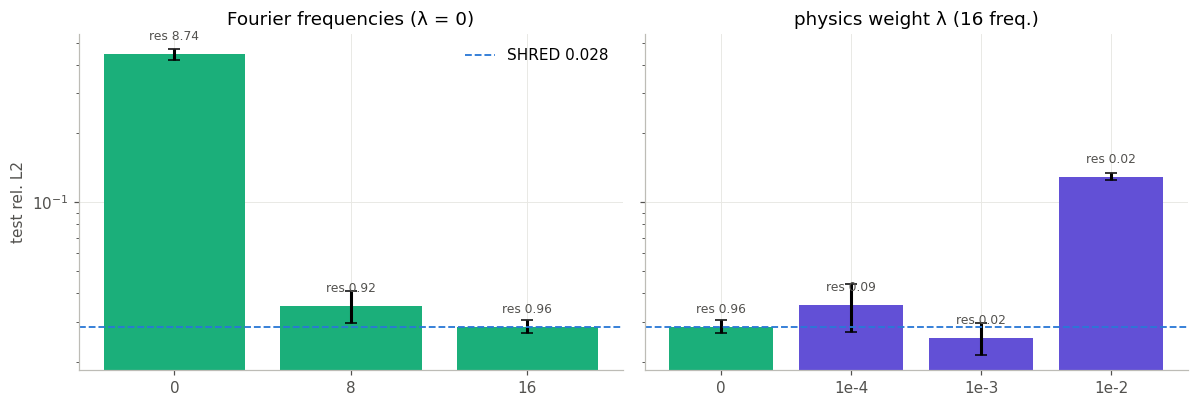

| Run | mean best validation (scaled) |
|---|---:|
| trunk, no Fourier features | 0.1998 |
| trunk, 8 frequencies | 0.0163 |
| trunk, no physics | 0.0135 |
| trunk + physics λ=1e-4 | 0.0176 |
| trunk + physics | 0.0118 |
| trunk + physics λ=1e-2 | 0.0573 |

In [8]:
def err(r):
    v = [results[(r, s)]["metrics"]["clean"]["err"] for s in SEEDS if (r, s) in results]
    return np.mean(v), np.std(v)

groups = [("Fourier frequencies (λ = 0)", [("0", "trunk_shred_noff__clean"), ("8", "trunk_shred_ff8__clean"),
                                           ("16", "trunk_shred__clean")]),
          ("physics weight λ (16 freq.)", [("0", "trunk_shred__clean"), ("1e-4", "trunk_shred_pinn_weak__clean"),
                                           ("1e-3", "trunk_shred_pinn__clean"), ("1e-2", "trunk_shred_pinn_strong__clean")])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
shred_mu = err("shred__clean")[0]
for ax, (title, items) in zip(axes, groups):
    mu, sd_ = zip(*(err(r) for _, r in items))
    ax.bar(range(len(items)), mu, yerr=sd_, capsize=4, color=["#6250d6" if "pinn" in r else "#1baf7a" for _, r in items])
    for i, (_, r) in enumerate(items):
        res = np.mean([RES[(r, s)][0] for s in SEEDS if (r, s) in RES])
        ax.text(i, mu[i] * 1.15, f"res {res:.2f}", ha="center", fontsize=8, color=gp.TEXT)
    ax.axhline(shred_mu, color=gp.method_color("shred__clean"), ls="--", lw=1.2, label=f"SHRED {shred_mu:.3f}")
    ax.set(xticks=range(len(items)), xticklabels=[k for k, _ in items], title=title, yscale="log")
axes[0].set_ylabel("test rel. L2"); axes[0].legend(frameon=False)
fig.tight_layout(); gp.save(fig, ROOT, "search"); plt.show()

rows = ["| Run | mean best validation (scaled) |", "|---|---:|"]
for r in [r for _, r in groups[0][1]] + [r for _, r in groups[1][1][1:]]:
    rows.append(f"| {LABEL[r]} | {np.mean([load_arrays(ROOT, r, s)['val_history'].min() for s in SEEDS]):.4f} |")
display(Markdown("\n".join(rows)))

## Conclusion

Tentative: one wave trajectory, clean data, interleaved split, 3 seeds.

**In one line: the trunk can be made to satisfy the PDE at no accuracy cost, but the physics adds nothing the
model uses. It only makes the unsupervised τ-direction self-consistent.**

1. **Accuracy at τ = 0 matches SHRED.** Test 0.0255 ± 0.0040 (physics) vs 0.0285 ± 0.0019 (trunk, no physics)
   vs 0.0285 ± 0.0065 (SHRED). The difference is within the seed spread (physics better on 2 of 3 seeds against
   either baseline), so no gain is established. 54k instead of 305k parameters, and smooth reconstructions
   where SHRED's per-pixel decoder is noisy.
2. **The physics is enforced.** Wave residual 0.024 vs 0.96, and the learned field follows the dispersion
   relation ωₖ = πck/L (median deviation 1 % vs 79 %) for every mode that carries energy. Note that 0.96 does
   not mean "badly unphysical": the metric is ≈ 1 for any field without time dynamics (u_ττ ≈ 0).
3. **Neither model learned anything about time.** Over the window, both track the trivial baseline that copies
   the τ = 0 field back almost exactly (seed 0, τ = −9 dt: 0.385 and 0.391 vs 0.381). Their velocity û_t at
   τ = 0 is uncorrelated with the truth (relative error ≈ 1.0 for both). The PDE constrains u_ττ given u, but
   nothing supervises u_t: the data loss only sees τ = 0. So physics makes the field over the window a
   self-consistent wave, starting from a velocity that is effectively arbitrary. The branch sees all 10 probe
   frames, so the information is in the input; it is just never asked for.
4. **The design cannot show a physics benefit.** Interleaved split: test windows sit between overlapping training
   windows, so the test task is interpolation (see `physical_relation`). Clean data only. A physics prior should
   matter under extrapolation (block split), little data, or noisy or faulty probes, none of which is tested.
   "No gain" means "not testable here", not "physics does not help".
5. **Fourier features are necessary.** Without them the trunk fails (0.44); 8 frequencies give 0.035, 16 give
   0.0285. Spectral bias is the likely cause, but learning rate and epochs were not varied.
6. **λ = 1e-3.** 1e-2 over-regularises (0.129, the field is pulled toward u = 0); 1e-4 barely enforces the PDE
   (residual 0.09) and is no better (0.035). Chosen on seed-0 test error; validation over 3 seeds picks the same.

**Caveats.** The Fourier features sin(kπx/L) contain the wave's exact spatial modes, so the trunk is handed the
spatial basis; Nektar has no such basis. The slab is thin (9 dt ≈ 0.036 vs a 0.2 period for mode 10). Wall
time ≈ 5× SHRED, measured with 3 seeds training in parallel (rough). Collocation sampling uses the global torch
RNG, so λ > 0 runs also get a different batch order than λ = 0 runs.

**Leads (not tried).** Give the model a signal for u_t: supervise the trunk at the probe locations for all 10 τ
(probe readings at every lag are already known, so no new targets and no leakage). Then test where a prior can
show: a block split, noise, faults.